# 02 — Methods & Evaluation (v3, DAD)

How v3 turns raw captures into detected attacks, and how we evaluate that **honestly** on the dataset's
**real** labels. Structure:

**Part 1 — Correctness of the data layer** (parsing == the paper; missingness; imbalance)
**Part 2 — The detection methods** (two channels + three fusions)
**Part 3 — Evaluation** (metrics explained; the full comparison; the honest findings)
**Part 4 — The trust gate** (query engine == pandas; independent verification)

Run **Restart & Run All** (after `bash tools/get_dad_dataset.sh`).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import preprocess, features, channels, fusion, experiment
from src import evaluation as ev, query_engine as qe
plt.rcParams["figure.figsize"] = (9, 3); plt.rcParams["axes.grid"] = True
df = preprocess.load_week()
print("loaded", df.shape)

loaded (101583, 10)


## Part 1 — Correctness of the data layer

### 1.1 Parsing reproduces the published ground truth
The pcap→table parse must be exactly right or every downstream number is wrong. We lock it to the paper's
schedule (Wed 104, Thu 56, Fri/Sat 192; **544** total).

In [2]:
per_day = qe.attacks_by_day(df)
print("per-day attacks:", per_day, "| total:", qe.count_attacks(df))
assert qe.count_attacks(df) == 544 and list(per_day.values()) == [0,0,104,56,192,192,0]
print("parsing == paper schedule ✓")

per-day attacks: {'mon': 0, 'tue': 0, 'wed': 104, 'thu': 56, 'fri': 192, 'sat': 192, 'sun': 0} | total: 544
parsing == paper schedule ✓


### 1.2 Missing data
The capture is essentially complete: **0** PUBLISH packets lack a temperature; only ~**0.6%** of the
value grid (sensor × 5-min window) is missing (a dropped/late message). We interpolate those on the
**value** channel only — the **flow** channel keeps its gaps because *missing messages are the
interception signal*. (Full audit: `report/DATA_QUALITY.md`.)

In [3]:
s = features.sensor_series(df, "5min")
print("PUBLISH packets missing temperature:", int(df.loc[df.topic=='IoT','temperature'].isna().sum()))
print("value-grid NaN fraction: %.3f  (per-sensor max %.3f)" % (s.isna().mean().mean(), s.isna().mean().max()))

PUBLISH packets missing temperature: 0
value-grid NaN fraction: 0.006  (per-sensor max 0.023)


### 1.3 Class imbalance
Attacks are **rare** (as real attacks are). We respect it — no resampling — and evaluate with
imbalance-aware metrics (below).

In [4]:
wl = features.window_labels(df, "5min")
print("packet imbalance : %d normal : %d attack  (%.2f%%, ~%d:1)" % (
      (df.label==0).sum(), (df.label==1).sum(), df.label.mean()*100, (df.label==0).sum()//max((df.label==1).sum(),1)))
print("window imbalance : %d : %d  (%.2f%%)" % ((wl.label==0).sum(), (wl.label==1).sum(), wl.label.mean()*100))
print("per-type windows :", wl[wl.label==1].attack_type.value_counts().to_dict())

packet imbalance : 101039 normal : 544 attack  (0.54%, ~185:1)
window imbalance : 1926 : 90  (4.46%)
per-type windows : {'mixed': 60, 'modification': 26, 'duplication': 4}


## Part 2 — The detection methods

### 2.1 Two complementary channels
| attack | changes | detector |
| --- | --- | --- |
| modification | the temperature *value* | **value** channel: max &#124;z&#124; of temperature |
| duplication | more messages / shorter gaps | **flow** channel: Isolation Forest on traffic features |
| interception | fewer messages / longer gaps | **flow** channel |


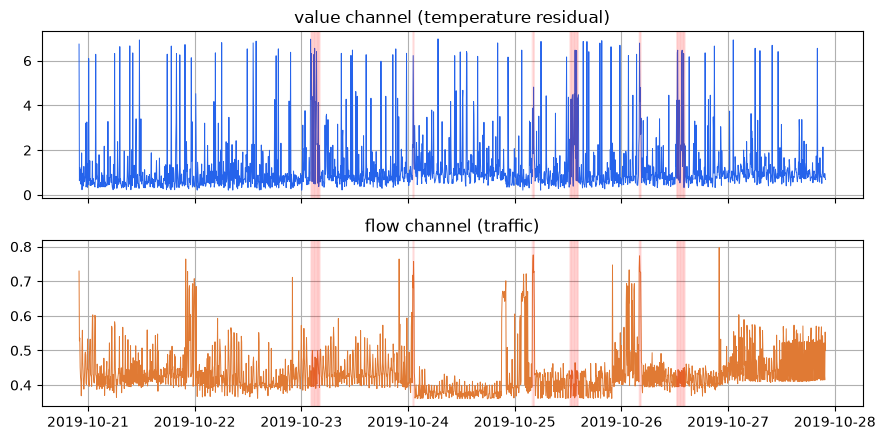

In [5]:
labels = features.window_labels(df, "5min")
flow    = features.flow_features(df, "5min").reindex(labels.index).fillna(0.0)
sensors = features.sensor_series(df, "5min", fill=True).reindex(labels.index)
value_s = channels.value_score(sensors)
flow_s  = channels.flow_score(flow)
atk = labels[labels.label == 1]
fig, ax = plt.subplots(2,1, figsize=(9,4.5), sharex=True)
ax[0].plot(value_s.index, value_s, color="#2563eb", lw=0.7); ax[0].set_title("value channel (temperature residual)")
ax[1].plot(flow_s.index, flow_s, color="#e07a34", lw=0.7); ax[1].set_title("flow channel (traffic)")
for a in ax:
    for t in atk.index: a.axvline(t, color="red", alpha=0.04)
plt.tight_layout(); plt.show()

### 2.2 Fusing the channels
- **late** — rank-normalise + max (an OR of specialists), **early** — concat features → one Isolation
  Forest, **supervised** — logistic regression over the two scores with **day-blocked** CV (so an attack
  episode never spans train and test).

In [6]:
y = labels.label.to_numpy()
late  = fusion.late_fusion(value_s, flow_s, "max")
vfeat = channels.value_features(sensors)
early = fusion.early_fusion(vfeat, flow)
print("late  AP:", round(ev.average_precision(late.to_numpy(), y),3))
print("early AP:", round(ev.average_precision(early.to_numpy(), y),3))

late  AP: 0.171
early AP: 0.147


## Part 3 — Evaluation

### 3.1 Which metrics, and why
Accuracy is useless under 21:1 imbalance (always-normal scores ~95%). We use:
- **Precision / Recall / F1** at the best threshold.
- **Average Precision (AP)** — area under the PR curve, *threshold-free*.
- **Point-adjusted** recall — event-level: catching any window of an attack episode counts the whole episode.
- **95% bootstrap CI** on AP — the uncertainty from resampling the windows.

In [7]:
res = experiment.run_experiment(df)
res[["config","AP","AP_lo","AP_hi","f1","precision","recall","f1_pa","recall_pa"]].round(3)

,config,AP,AP_lo,AP_hi,f1,precision,recall,f1_pa,recall_pa
0,flow_only,0.136,0.077,0.222,0.226,0.412,0.156,0.294,0.178
1,value_only,0.183,0.136,0.245,0.379,0.331,0.444,0.804,0.889
2,early_fusion,0.147,0.108,0.206,0.289,0.202,0.511,0.732,1.000
3,late_fusion,0.171,0.123,0.246,0.306,0.214,0.533,0.789,1.000
4,supervised,0.101,0.075,0.141,0.212,0.147,0.378,0.554,1.000


In [8]:
res[["config","recall_modification","recall_duplication","recall_mixed"]].round(3)

,config,recall_modification,recall_duplication,recall_mixed
0,flow_only,0.000,1.0,0.167
1,value_only,0.462,0.5,0.433
2,early_fusion,0.423,1.0,0.517
3,late_fusion,0.462,1.0,0.533
4,supervised,0.423,1.0,0.317


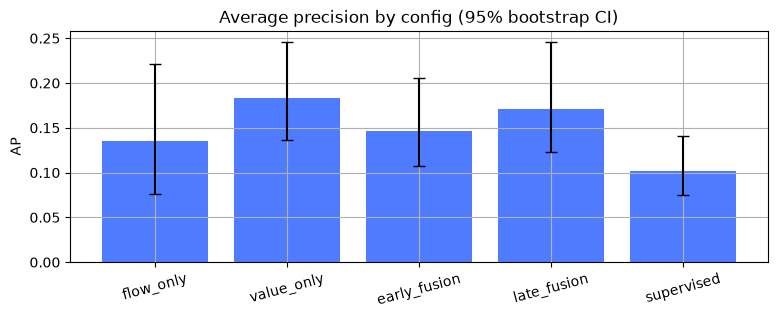

In [9]:
plt.bar(res.config, res.AP, yerr=[res.AP-res.AP_lo, res.AP_hi-res.AP], capsize=4, color="#4f7cff")
plt.title("Average precision by config (95% bootstrap CI)"); plt.ylabel("AP"); plt.xticks(rotation=15); plt.show()

### 3.2 The honest findings
1. **Complementarity is real:** `flow_only` has **0.00** recall on *modification* but **1.00** on
   *duplication*; the value channel is the opposite. Each is blind to the other's attack.
2. **Fusion trades precision for recall** and reaches **1.00 point-adjusted recall** (catches every attack
   *episode*).
3. **But the AP confidence intervals overlap**, so *no config is significantly best on AP* — the point
   estimate alone would mislead.
4. **The *supervised* combiner is the worst.** Under honest day-blocked CV it overfits, because attack
   *type* is confounded with *day* so the learned weighting doesn't transfer — a caution about scarce,
   clustered labels. (A random split would have leaked and looked great.) Full analysis: `report/MODELS.md`.

## Part 4 — The trust gate

### 4.1 Every query == pandas
The answers depend on the query engine being exactly right. Each function equals a direct pandas
computation.

In [10]:
for stat in ("max","min","mean"):
    got = qe.temperature_stat(df, stat); exp = float(getattr(df.temperature.dropna(), stat)())
    print(f"temperature {stat}: query={got:.4f}  pandas={exp:.4f}  match={got==exp}")

temperature max: query=29.4000  pandas=29.4000  match=True
temperature min: query=8.6700  pandas=8.6700  match=True
temperature mean: query=18.4259  pandas=18.4259  match=True


### 4.2 Independent verification
`verify_results.py` recomputes the headline numbers a **second way** (e.g. summing the raw label CSVs,
independent of the pcap parse) — **12/12** checks. Run it from the project root:
```bash
python3.12 verify_results.py
```


## Findings
DAD's **real** labels + proper, imbalance-aware, event-level metrics with confidence intervals give an
honest verdict: the two views are complementary, fusion catches every episode but no config is
significantly best on AP, and a learned combiner *underperforms* under honest CV. The truth layer is
verifiably exact (== pandas, 12/12). See also `report/EVALUATION.md` and `report/MODELS.md`.